# US Treasury Yield Curve Analysis: Trump Tariff Threats Impact

This notebook analyzes the dynamics of the US Government Yield Curve around Trump tariff threat announcements using FRED (Federal Reserve Economic Data) API.

In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import requests
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8')
plt.rcParams['figure.figsize'] = (12, 8)

In [2]:
import sys
import os

# Add parent directory to path to access other folders
parent_dir = os.path.dirname(os.getcwd())
sys.path.append(parent_dir)

## FRED API Setup

This notebook loads the FRED API key from a separate file to keep it secure when sharing.

### Setup Instructions:

1. **Get FRED API Key**: Register at https://fred.stlouisfed.org/docs/api/api_key.html
2. **Create API Key File**: Create the file `../data/fred/api_key.py` (relative to this notebook)
3. **Add Your Key**: In that file, add:
   ```python
   FRED_API_KEY = 'your_actual_api_key_here'
   ```

### File Structure:
```
FIN2764/
├── functions_library/
│   └── fred.py  # Download functionality 
├── module_1/
│   └── pylab_trump_tariff_threats_assignment.ipynb  # This notebook
└── data/
    └── fred/
        └── api_key.py  # Your API key file (not shared)
```

The notebook will automatically load your API key from this secure location.

In [3]:
# FRED API Configuration
# API key is loaded from a separate file for security
try:
    from data.fred.api_key import FRED_API_KEY
    print("✅ FRED API key loaded successfully from data/fred/api_key.py")
except ImportError:
    print("⚠️  Could not load FRED API key from data/fred/api_key.py")
    print("Please ensure the file exists with the variable 'FRED_API_KEY'")
    FRED_API_KEY = None

✅ FRED API key loaded successfully from data/fred/api_key.py


## Trump Tariff Threats Timeline

Key dates for analysis based on major tariff announcements during Trump administrations:

In [4]:
# NOTE (group): the original template stored events in dicts keyed by date.
# Python dicts silently drop duplicate keys, so two events were lost
# ('2025-08-06' in trump_actions and '2025-03-04' in country_responses).
# We store them as lists of (date, description) tuples instead - same content.

# Comprehensive Trump Tariff Events Timeline (Updated through August 18, 2025)
# Categorized by Trump actions/threats vs. retaliatory responses

trump_actions = [
    # Trump First Term (2017-2021)
    ('2017-01-23', 'TPP Withdrawal announced'),
    ('2017-04-20', 'Commerce Dept. Steel dumping investigation launched'),
    ('2018-01-22', 'Solar panel and washing machine tariffs (30% and 20%)'),
    ('2018-03-01', 'Steel and Aluminum Tariffs Announced (25% steel, 10% aluminum)'),
    ('2018-03-22', 'China Tariffs Announced ($60B worth of Chinese goods)'),
    ('2018-04-03', 'China tariff list published ($50B in goods, 25%)'),
    ('2018-06-15', 'China Tariffs List Published (25% on $50B of goods)'),
    ('2018-07-06', 'First China tariffs take effect ($34B)'),
    ('2018-08-23', 'Second tranche China tariffs ($16B)'),
    ('2018-09-17', 'China Tariffs Phase 2 Announced (10% on additional $200B)'),
    ('2018-09-24', 'China tariffs Phase 2 implemented ($200B at 10%)'),
    ('2019-05-05', 'China Tariff Escalation Tweet (25% on $200B)'),
    ('2019-05-10', 'China tariffs raised to 25% ($200B worth)'),
    ('2019-08-01', 'China Tariffs Phase 3 Announced (10% on remaining $300B)'),
    ('2019-08-23', 'China tariff escalation tweet (existing and new tariffs)'),
    ('2019-09-01', 'China tariffs on $300B begin (15% on $112B)'),
    ('2019-12-15', 'Planned China tariff increase postponed (trade deal progress)'),
    ('2020-01-15', 'Phase One China trade deal signed'),
    # Trump Second Term (2025) - Comprehensive Timeline
    ('2025-01-20', 'Inauguration - pledged immediate trade system overhaul'),
    ('2025-01-22', 'Executive order directing tariff review within 60 days'),
    ('2025-02-01', 'National emergency declared - 25% tariffs on Canada/Mexico, 10% on China (IEEPA)'),
    ('2025-02-10', 'Steel/aluminum tariff expansion - ended exemptions, raised aluminum to 25%'),
    ('2025-02-13', 'Announced reciprocal tariffs on all countries with trade barriers (April implementation)'),
    ('2025-02-21', 'Presidential memorandum investigating digital service taxes for retaliation'),
    ('2025-03-04', 'Chinese "fentanyl tariff" raised to 20% (USMCA tariffs suspended)'),
    ('2025-04-02', 'National emergency on trade deficit - 10% baseline tariff on all countries'),
    ('2025-04-05', 'Universal 10% tariff takes effect on nearly all imports'),
    ('2025-05-02', 'China/Hong Kong exemption removed again'),
    ('2025-07-02', 'Trade deal announced with Vietnam'),
    ('2025-07-04', 'One Big Beautiful Bill Act - eliminates de minimis exemption (2027)'),
    ('2025-07-07', 'Reciprocal tariffs delayed to August 1'),
    ('2025-07-08', 'Letters sent to 14 countries (Japan, S.Korea) threatening tariffs without deals'),
    ('2025-07-30', 'Cathode copper exempted from tariffs'),
    ('2025-08-06', 'Secondary tariff on India (25% additional) for buying Russian oil'),
    ('2025-08-06', 'Tariff rates finalized: Canada 35%, Mexico 30%, China 34%, EU 20%, Japan 24%'),
    ('2025-08-15', 'Brazil hit with 50% tariffs, India total 50%, various Asian countries 25-36%'),
    ('2025-08-29', 'De minimis exemption ended early (originally scheduled 2027)'),
]

country_responses = [
    # China Responses (First Term)
    ('2018-04-02', 'China retaliatory tariffs announced ($3B US goods)'),
    ('2018-04-04', 'China escalates retaliation ($50B US goods, 25%)'),
    ('2018-06-16', 'China announces retaliatory tariffs ($50B)'),
    ('2018-07-06', 'China implements retaliatory tariffs ($34B)'),
    ('2018-08-03', 'China tariffs on $60B US goods (5-25%)'),
    ('2018-08-23', 'China retaliates on $16B US goods'),
    ('2018-09-18', 'China announces tariffs on $60B US goods'),
    ('2018-09-24', 'China implements tariffs on $60B US goods'),
    ('2019-05-13', 'China raises tariffs on $60B US goods to 25%'),
    ('2019-08-05', 'China allows yuan to weaken past 7/USD'),
    ('2019-08-23', 'China announces tariffs on $75B US goods'),
    ('2019-09-01', 'China implements tariffs on $75B US goods'),
    ('2019-12-19', 'China announces tariff reductions (Phase One)'),
    # EU Responses (First Term)
    ('2018-03-02', 'EU threatens retaliation on steel/aluminum tariffs'),
    ('2018-06-22', 'EU implements retaliatory tariffs ($3.2B US goods)'),
    ('2018-11-02', 'EU complains to WTO about US auto tariff threats'),
    # Canada/Mexico Responses (First Term)
    ('2018-05-31', 'Canada announces retaliatory tariffs ($16.6B)'),
    ('2018-07-01', 'Canada implements steel/aluminum retaliation'),
    ('2018-06-05', 'Mexico announces retaliatory tariffs (steel, pork, bourbon)'),
    # Other Countries (First Term)
    ('2018-03-26', 'India raises tariffs on US almonds, apples'),
    ('2018-06-21', 'Turkey raises tariffs on US goods (rice, cars, alcohol)'),
    ('2018-08-10', 'Russia considers tariffs on US goods'),
    # Second Term Responses (2025) - Major Escalation
    ('2025-02-02', 'Canada, Mexico, China condemn tariffs as "unjustified"'),
    ('2025-03-04', 'Canada implements immediate 25% counter-tariffs on $20B US imports'),
    ('2025-03-04', 'China retaliates with 10-15% tariffs on US agricultural imports'),
    ('2025-03-05', 'Mexico announces retaliatory measures (5-20% on pork, cheese, steel)'),
    ('2025-03-15', 'China adds 15 US companies to export control list'),
    ('2025-04-04', 'EU announces $100B counter-tariffs if 30% rate implemented'),
    ('2025-04-06', 'China escalates to 145% tariffs on US goods (US at 145% on China)'),
    ('2025-04-10', 'Brazil passes reciprocity bill allowing tariff retaliation'),
    ('2025-05-28', 'Court of International Trade declares Trump tariff orders invalid'),
    ('2025-06-15', 'Canada provinces boycott US spirits amid trade war'),
    ('2025-07-12', 'Japan threatens "all options on table" for tariff response'),
    ('2025-07-20', 'EU confirms 30% counter-tariffs on $100B US goods'),
    ('2025-08-01', 'Malaysian government rules out retaliatory tariffs'),
    ('2025-08-05', 'New Zealand announces no retaliation plans'),
    ('2025-08-08', 'India maintains higher tariffs than US on various products (80% rice, 50% apples)'),
    ('2025-08-10', 'Brazil president vows reciprocation but holds back on steel/aluminum'),
    ('2025-08-12', 'China continues agricultural tariff escalation (chicken, wheat, corn 15%)'),
    ('2025-08-15', 'EU-Canada-China coordination on $330B retaliatory measures'),
]

## Treasury Yield Curve Data from FRED

We'll fetch key Treasury yields across different maturities to construct the yield curve.

### Set of yield to fetch from FRED 

In [5]:
# Treasury yield series from FRED
treasury_series = {
    '3M': 'DGS3MO',    # 3-Month Treasury Constant Maturity Rate
    '6M': 'DGS6MO',    # 6-Month Treasury Constant Maturity Rate
    '1Y': 'DGS1',      # 1-Year Treasury Constant Maturity Rate
    '2Y': 'DGS2',      # 2-Year Treasury Constant Maturity Rate
    '3Y': 'DGS3',      # 3-Year Treasury Constant Maturity Rate
    '5Y': 'DGS5',      # 5-Year Treasury Constant Maturity Rate
    '7Y': 'DGS7',      # 7-Year Treasury Constant Maturity Rate
    '10Y': 'DGS10',    # 10-Year Treasury Constant Maturity Rate
    '20Y': 'DGS20',    # 20-Year Treasury Constant Maturity Rate
    '30Y': 'DGS30',    # 30-Year Treasury Constant Maturity Rate
}

### Load functions to fetch data from FRED

In [6]:
from functions_library.module_1.fred import fetch_yield_curve_data

# Group's event-study toolkit (documented in functions_library/module_1/event_study.py)
from functions_library.module_1.event_study import (
    MATURITIES, MATURITY_YEARS, COMPONENTS,
    fetch_yield_curve_treasury, prepare_yields, build_event_table, decluster_events,
    event_study, summary_table, window_effect, compare_table, pca_factors,
    plot_paths, plot_curve_change, plot_compare_paths,
)

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(250)
pl.Config.set_fmt_str_lengths(120)

FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

### Fetch the Data

Now let's fetch the Treasury yield curve data:

In [7]:

# Sample period (ASSUMPTION): starts in 2015, i.e. well over 30 trading days before the
# first event (Jan 2017), and ends on 2026-10-22 (the last FRED observation is 2026-10-21), well after the last event (Aug 2025),
# so that every [-30,+30] window is complete. (fred.py's default end date, 2025-08-01,
# would cut the post-event window of all events from July 2025 onwards.)
START_DATE = '2015-01-01'
END_DATE = '2026-10-22'

# The data are saved once in data/fred/ so that results are reproducible.
# Set REFRESH_DATA = True to download them again (from FRED if an API key is available).
REFRESH_DATA = False
SNAPSHOT = os.path.join(parent_dir, 'data', 'fred', 'yield_curve_snapshot.csv')

if os.path.exists(SNAPSHOT) and not REFRESH_DATA:
    yield_curve_data = pl.read_csv(SNAPSHOT, try_parse_dates=True)
    print(f"Loaded saved data snapshot: {SNAPSHOT}")
elif FRED_API_KEY is not None:
    yield_curve_data = fetch_yield_curve_data(treasury_series, START_DATE, END_DATE, FRED_API_KEY)
    yield_curve_data.write_csv(SNAPSHOT)
else:
    # Fallback without a FRED key: the same constant-maturity yields downloaded directly
    # from the US Treasury, which is the original source of the FRED DGSxx series.
    yield_curve_data = fetch_yield_curve_treasury(START_DATE, END_DATE)
    yield_curve_data.write_csv(SNAPSHOT)

print(f"Data range: {yield_curve_data['date'].min()} to {yield_curve_data['date'].max()}, shape {yield_curve_data.shape}")


Loaded saved data snapshot: FIN2764/data/fred/yield_curve_snapshot.csv
Data range: 2015-01-02 to 2026-10-21, shape (2952, 11)


In [8]:
yield_curve_data

date,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,20Y,30Y
date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2015-01-02,0.02,0.11,0.25,0.66,1.07,1.61,1.92,2.12,2.41,2.69
2015-01-05,0.03,0.1,0.26,0.68,1.06,1.57,1.85,2.04,2.32,2.6
2015-01-06,0.03,0.1,0.25,0.65,1.02,1.5,1.78,1.97,2.25,2.52
2015-01-07,0.03,0.09,0.25,0.62,1.0,1.47,1.76,1.96,2.25,2.52
2015-01-08,0.03,0.08,0.23,0.62,1.0,1.5,1.81,2.03,2.33,2.59
2015-01-09,0.02,0.08,0.22,0.59,0.96,1.45,1.75,1.98,2.29,2.55
2015-01-12,0.03,0.09,0.19,0.56,0.91,1.39,1.69,1.92,2.23,2.49
2015-01-13,0.03,0.08,0.2,0.54,0.88,1.37,1.67,1.91,2.24,2.49
2015-01-14,0.04,0.09,0.18,0.51,0.83,1.33,1.62,1.86,2.2,2.47


## Event Study Analysis

We want to analyze the abnormal yield curve change around specific events by:
- For all event dates in the sample, measure the yield curve change (relative to the yield on the event date) over a window of [-30,+30] business days.
- Measure the abnormal yield change as the average yield changes over all identified event windows vs the average of all other non-event dates.

### Methodology and assumptions (group)

**Measurement** (as required by the assignment):

* For each event day $t_e$ and each maturity $m$, the yield change relative to the event date over the window
  $\tau\in[-30,+30]$ trading days is $\Delta y_{e,m}(\tau) = y_m(t_e+\tau) - y_m(t_e)$ (in bp), so that $\Delta y(0)=0$.
  A negative value at $\tau=-30$ means yields were *lower* 30 days before the event, i.e. they *rose* into the event.
* The **abnormal yield change** is $AYC_m(\tau) = \frac{1}{N}\sum_e \Delta y_{e,m}(\tau) - \frac{1}{|ND|}\sum_{d\in ND}\Delta y_{d,m}(\tau)$,
  where $ND$ is the set of all non-event trading days (with a full window available).

**Assumptions** (highlighted for grading):

1. *Data*: daily Treasury constant-maturity (par) yields 3M-30Y (FRED `DGSxx`), 2015-01-02 to 2026-10-21 (last FRED observation available). Days on which all
   yields are missing (market holidays in FRED) are dropped; isolated missing values are forward-filled.
2. *Event timing*: events dated on a weekend/holiday are assigned to the **next trading day**. Events that fall on the same trading
   day are merged into a single event.
3. *Normal days*: the benchmark excludes **every** tariff-related day (Trump actions *and* country responses), not only the events of the
   sample being analysed.
4. *Curve components*: Level = average of the 10 maturities; Slope = 10Y - 3M; Curvature = 2 x 5Y - 2Y - 10Y (butterfly).
   A PCA-based alternative is shown in Q2.
5. *Inference*: significance is assessed with a **placebo test**: 2,000 random samples (with replacement) of normal days of the same
   size as the event sample; the grey bands in the plots are the 2.5%-97.5% percentiles of the placebo AYC, and p-values are
   two-sided. Stars in tables: \*\*\* 1%, \*\* 5%, \* 10%.
6. *Country tagging*: the country/region of each event is identified with keyword rules on its description (see `REGION_PATTERNS`
   in `event_study.py`); an event naming several countries counts in each of them.
7. *Mandates*: events before 2021-01-20 belong to the first term, events after to the second term.

The complete and final list of assumptions (8, including the definition of business days and the FOMC dates) is in Section 2.6 of the report.

## Data preparation

In [9]:
yields = prepare_yields(yield_curve_data)
dates = yields['date']
print(f"Clean panel: {yields.shape[0]} trading days, {dates.min()} to {dates.max()}")
yields.head()

Clean panel: 2952 trading days, 2015-01-02 to 2026-10-21


date,3M,6M,1Y,2Y,3Y,5Y,7Y,10Y,20Y,30Y,Level,Slope,Curvature
date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2015-01-02,0.02,0.11,0.25,0.66,1.07,1.61,1.92,2.12,2.41,2.69,1.286,2.1,0.44
2015-01-05,0.03,0.1,0.26,0.68,1.06,1.57,1.85,2.04,2.32,2.6,1.251,2.01,0.42
2015-01-06,0.03,0.1,0.25,0.65,1.02,1.5,1.78,1.97,2.25,2.52,1.207,1.94,0.38
2015-01-07,0.03,0.09,0.25,0.62,1.0,1.47,1.76,1.96,2.25,2.52,1.195,1.93,0.36
2015-01-08,0.03,0.08,0.23,0.62,1.0,1.5,1.81,2.03,2.33,2.59,1.222,2.0,0.35


## Event tables

In [10]:
actions = build_event_table(trump_actions, 'Trump action', dates)
responses = build_event_table(country_responses, 'Country response', dates)

# every tariff-related trading day: excluded from the pool of "normal" days
all_event_idx = np.union1d(actions['idx'].to_numpy(), responses['idx'].to_numpy())

print(f"Trump actions:     {len(trump_actions)} listed -> {len(actions)} distinct event trading days")
print(f"Country responses: {len(country_responses)} listed -> {len(responses)} distinct event trading days")
print(f"All tariff-related trading days: {len(all_event_idx)}")
display(pl.concat([actions, responses]).group_by(['category', 'term']).len().sort(['category', 'term']))
display(responses.explode('regions').group_by('regions').len().sort('regions'))

Trump actions:     37 listed -> 35 distinct event trading days
Country responses: 40 listed -> 39 distinct event trading days
All tariff-related trading days: 65


category,term,len
str,str,u32
"""Country response""","""First term""",22
"""Country response""","""Second term""",17
"""Trump action""","""First term""",18
"""Trump action""","""Second term""",17


regions,len
str,u32
"""China""",19
"""EU""",6
"""Global / other""",1
"""North America""",8
"""Other countries""",9


In [11]:
actions.select(['trade_date', 'term', 'regions', 'description'])

trade_date,term,regions,description
date,str,list[str],str
2017-01-23,"""First term""","[""Global / other""]","""TPP Withdrawal announced"""
2017-04-20,"""First term""","[""Global / other""]","""Commerce Dept. Steel dumping investigation launched"""
2018-01-22,"""First term""","[""Global / other""]","""Solar panel and washing machine tariffs (30% and 20%)"""
2018-03-01,"""First term""","[""Global / other""]","""Steel and Aluminum Tariffs Announced (25% steel, 10% aluminum)"""
2018-03-22,"""First term""","[""China""]","""China Tariffs Announced ($60B worth of Chinese goods)"""
2018-04-03,"""First term""","[""China""]","""China tariff list published ($50B in goods, 25%)"""
2018-06-15,"""First term""","[""China""]","""China Tariffs List Published (25% on $50B of goods)"""
2018-07-06,"""First term""","[""China""]","""First China tariffs take effect ($34B)"""
2018-08-23,"""First term""","[""China""]","""Second tranche China tariffs ($16B)"""


In [12]:
responses.select(['trade_date', 'term', 'regions', 'description'])

trade_date,term,regions,description
date,str,list[str],str
2018-03-02,"""First term""","[""EU""]","""EU threatens retaliation on steel/aluminum tariffs"""
2018-03-26,"""First term""","[""Other countries""]","""India raises tariffs on US almonds, apples"""
2018-04-02,"""First term""","[""China""]","""China retaliatory tariffs announced ($3B US goods)"""
2018-04-04,"""First term""","[""China""]","""China escalates retaliation ($50B US goods, 25%)"""
2018-05-31,"""First term""","[""North America""]","""Canada announces retaliatory tariffs ($16.6B)"""
2018-06-05,"""First term""","[""North America""]","""Mexico announces retaliatory tariffs (steel, pork, bourbon)"""
2018-06-18,"""First term""","[""China""]","""China announces retaliatory tariffs ($50B)"""
2018-06-21,"""First term""","[""Other countries""]","""Turkey raises tariffs on US goods (rice, cars, alcohol)"""
2018-06-22,"""First term""","[""EU""]","""EU implements retaliatory tariffs ($3.2B US goods)"""


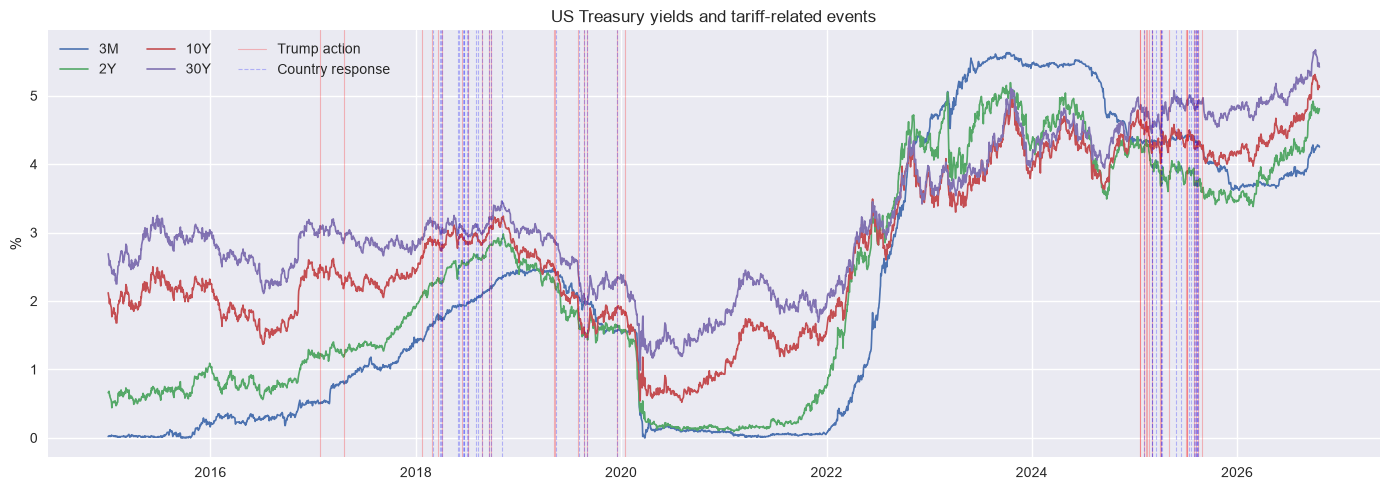

In [13]:
# Overview: yields over the sample with the event days
fig, ax = plt.subplots(figsize=(14, 5))
for m in ['3M', '2Y', '10Y', '30Y']:
    ax.plot(dates, yields[m], lw=1.2, label=m)
for i, d in enumerate(actions['trade_date']):
    ax.axvline(d, color='red', alpha=0.25, lw=0.8, label='Trump action' if i == 0 else None)
for i, d in enumerate(responses['trade_date']):
    ax.axvline(d, color='blue', alpha=0.25, lw=0.8, ls='--', label='Country response' if i == 0 else None)
ax.set_title('US Treasury yields and tariff-related events')
ax.set_ylabel('%')
ax.legend(ncol=3)
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig00_overview.png', dpi=150); fig.savefig(f'{FIG_DIR}/fig00_overview.pdf', bbox_inches='tight')
plt.show()

## Question 1.1 - Market reaction to Trump's announcements/actions

Event sample: all Trump actions/threats (first and second mandate).

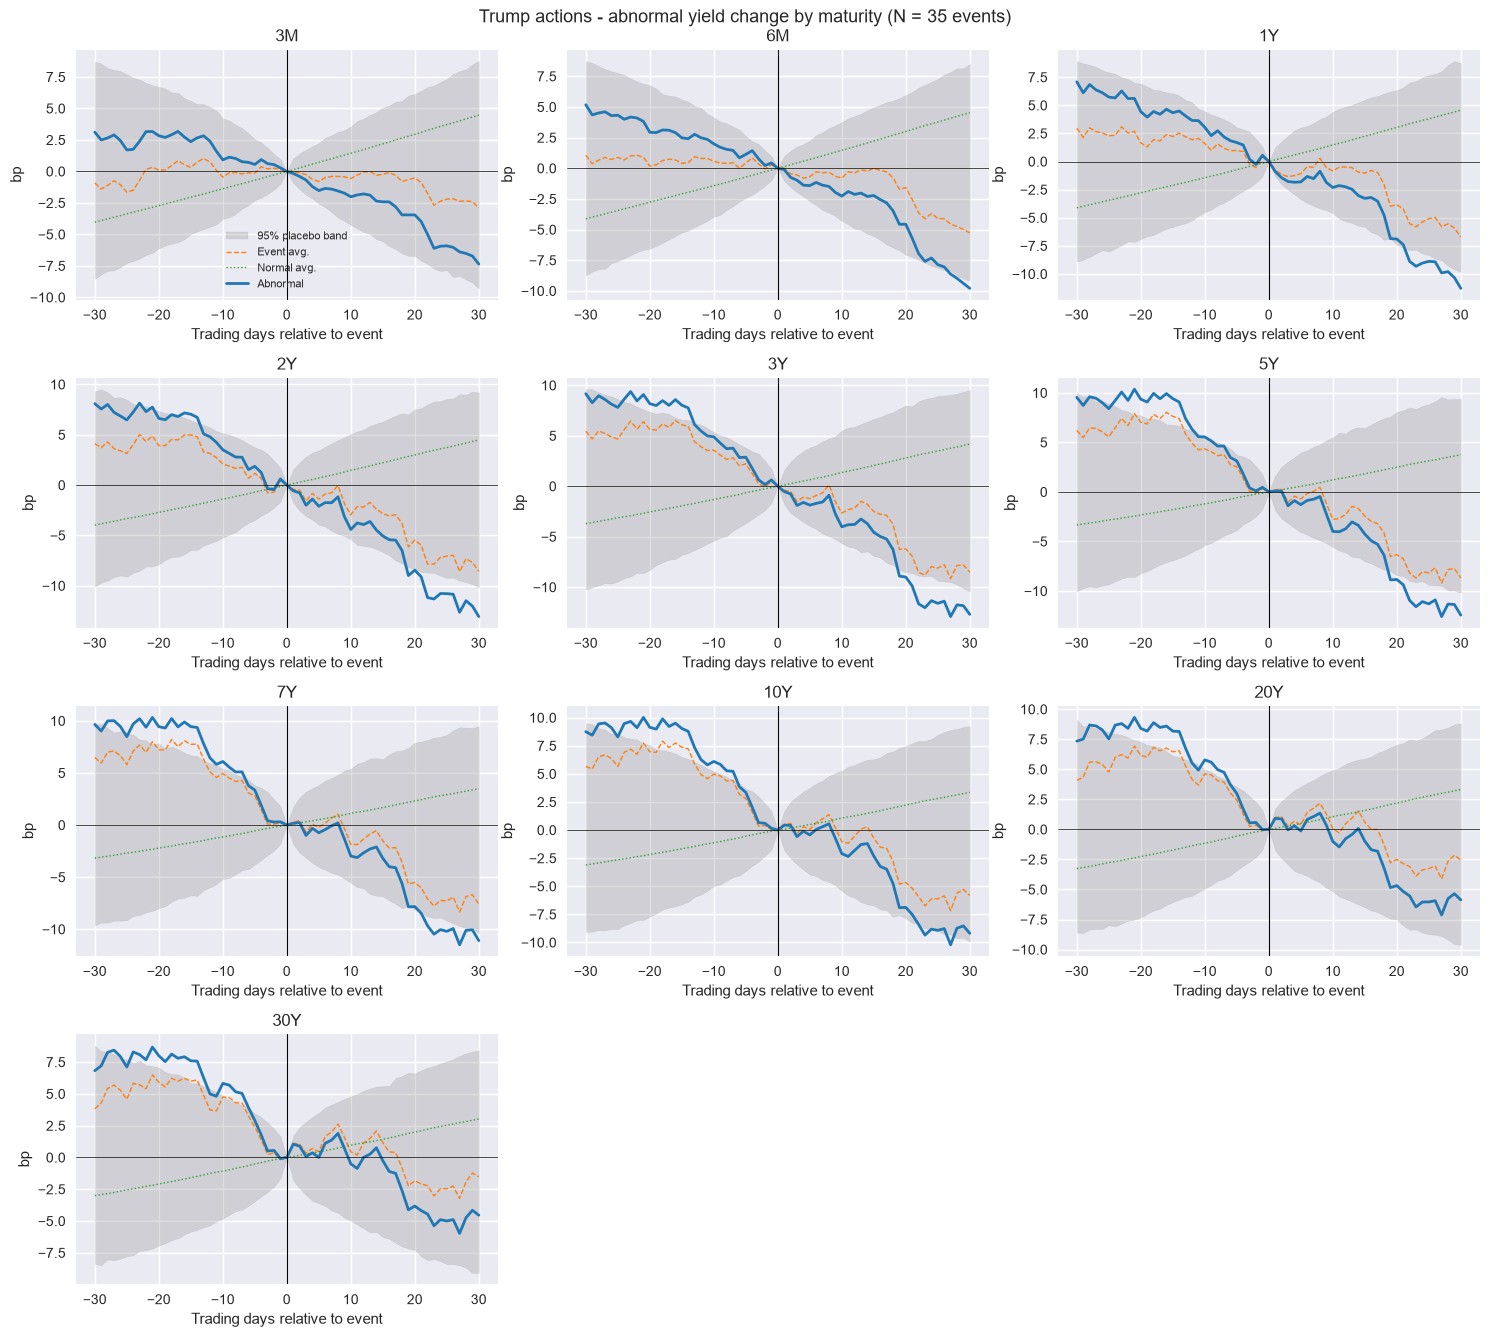

In [14]:
COLS = MATURITIES + COMPONENTS
res_actions = event_study(yields, actions['idx'], COLS, exclude_idx=all_event_idx)

fig = plot_paths(res_actions, MATURITIES, 'Trump actions - abnormal yield change by maturity',
                 savepath=f'{FIG_DIR}/fig01_actions_paths.png')
plt.show()

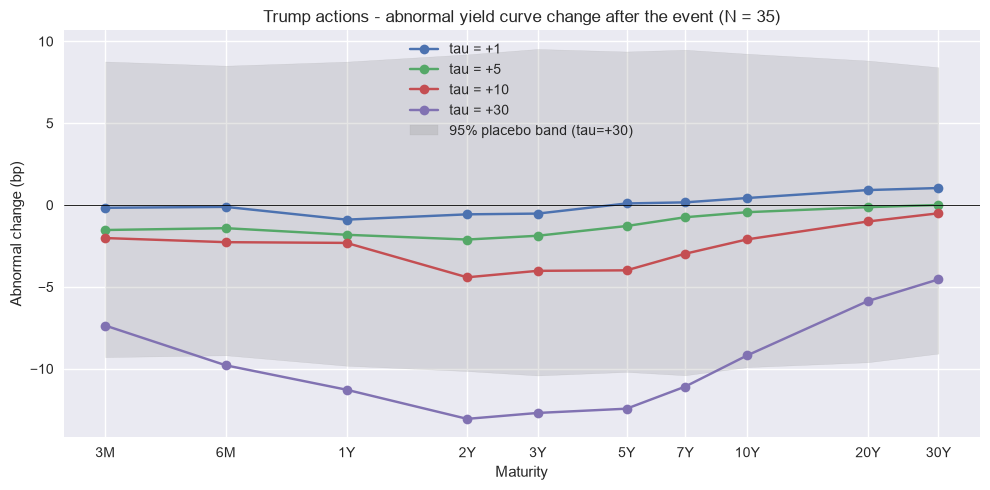

In [15]:
# Abnormal change of the whole curve at several horizons after the event
fig, ax = plt.subplots(figsize=(10, 5))
for tau in [1, 5, 10, 30]:
    p = int(np.where(res_actions['taus'] == tau)[0][0])
    ax.plot(MATURITY_YEARS, res_actions['abnormal'][p, :len(MATURITIES)], marker='o', label=f'tau = +{tau}')
p = int(np.where(res_actions['taus'] == 30)[0][0])
ax.fill_between(MATURITY_YEARS, res_actions['band_lo'][p, :len(MATURITIES)], res_actions['band_hi'][p, :len(MATURITIES)],
                color='grey', alpha=0.2, label='95% placebo band (tau=+30)')
ax.axhline(0, color='k', lw=0.6)
ax.set_xscale('log'); ax.set_xticks(MATURITY_YEARS); ax.set_xticklabels(MATURITIES)
ax.set_xlabel('Maturity'); ax.set_ylabel('Abnormal change (bp)')
ax.set_title(f"Trump actions - abnormal yield curve change after the event (N = {res_actions['n_events']})")
ax.legend()
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig02_actions_curve.png', dpi=150); fig.savefig(f'{FIG_DIR}/fig02_actions_curve.pdf', bbox_inches='tight')
plt.show()

In [16]:
# Abnormal change (bp) at selected horizons and placebo p-values
tab, pv = summary_table(res_actions)
print('Abnormal yield change (bp), relative to the event date:')
display(tab)
print('Placebo p-values:')
display(pv)

Abnormal yield change (bp), relative to the event date:


series,tau=-30,tau=-10,tau=-1,tau=+1,tau=+5,tau=+10,tau=+30
str,f64,f64,f64,f64,f64,f64,f64
"""3M""",3.1,0.9,0.3,-0.2,-1.5,-2.0,-7.4
"""6M""",5.2,2.0,0.4,-0.1,-1.4,-2.3,-9.8
"""1Y""",7.1,3.0,0.6,-0.9,-1.8,-2.3,-11.3
"""2Y""",8.1,3.5,0.6,-0.6,-2.1,-4.4,-13.1
"""3Y""",9.2,4.9,0.6,-0.5,-1.9,-4.0,-12.7
"""5Y""",9.5,5.5,0.5,0.1,-1.3,-4.0,-12.4
"""7Y""",9.7,6.1,0.3,0.2,-0.7,-3.0,-11.1
"""10Y""",8.8,6.1,0.2,0.4,-0.4,-2.1,-9.2
"""20Y""",7.3,5.8,-0.0,0.9,-0.1,-1.0,-5.9


Placebo p-values:


series,tau=-30,tau=-10,tau=-1,tau=+1,tau=+5,tau=+10,tau=+30
str,f64,f64,f64,f64,f64,f64,f64
"""3M""",0.452,0.614,0.542,0.716,0.186,0.282,0.096
"""6M""",0.228,0.291,0.384,0.804,0.24,0.236,0.032
"""1Y""",0.126,0.18,0.385,0.154,0.232,0.301,0.022
"""2Y""",0.1,0.184,0.481,0.506,0.242,0.1,0.014
"""3Y""",0.068,0.078,0.492,0.575,0.328,0.138,0.02
"""5Y""",0.062,0.042,0.621,0.907,0.513,0.154,0.017
"""7Y""",0.05,0.018,0.737,0.849,0.7,0.286,0.032
"""10Y""",0.066,0.016,0.848,0.619,0.824,0.426,0.057
"""20Y""",0.107,0.016,0.993,0.292,0.934,0.69,0.199


In [17]:
# Window effects: pre-event drift, announcement effect [-1,+1], short [0,+5] and full [0,+30] post-event
compare_table({'Trump actions': res_actions}, ['3M', '2Y', '5Y', '10Y', '30Y'])

sample,N,"3M [-30,+0]","2Y [-30,+0]","5Y [-30,+0]","10Y [-30,+0]","30Y [-30,+0]","3M [-1,+1]","2Y [-1,+1]","5Y [-1,+1]","10Y [-1,+1]","30Y [-1,+1]","3M [+0,+5]","2Y [+0,+5]","5Y [+0,+5]","10Y [+0,+5]","30Y [+0,+5]","3M [+0,+30]","2Y [+0,+30]","5Y [+0,+30]","10Y [+0,+30]","30Y [+0,+30]"
str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""Trump actions""",35,"""-3.1""","""-8.1""","""-9.5*""","""-8.8*""","""-6.8""","""-0.5""","""-1.2""","""-0.4""","""0.3""","""1.1""","""-1.5""","""-2.1""","""-1.3""","""-0.4""","""0.0""","""-7.4*""","""-13.1**""","""-12.4**""","""-9.2*""","""-4.5"""


### Discussion Q1.1

The discussion of Q1.1 is in Section 3 of the report (`main.pdf`). The figures and tables produced above are the ones used there.

## Question 1.2 - Level, slope and curvature

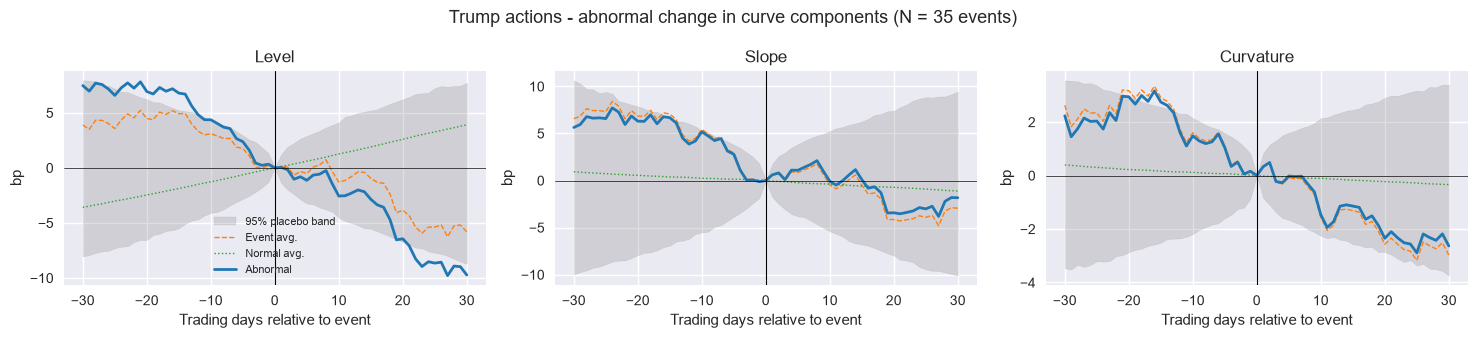

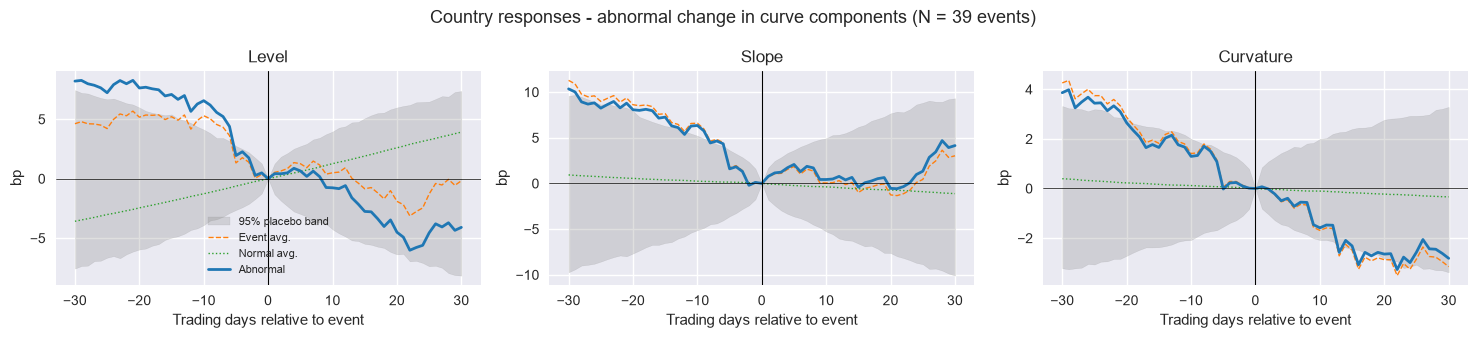

In [18]:
res_responses = event_study(yields, responses['idx'], COLS, exclude_idx=all_event_idx)

fig = plot_paths(res_actions, COMPONENTS, 'Trump actions - abnormal change in curve components',
                 savepath=f'{FIG_DIR}/fig03_actions_components.png')
plt.show()
fig = plot_paths(res_responses, COMPONENTS, 'Country responses - abnormal change in curve components',
                 savepath=f'{FIG_DIR}/fig04_responses_components.png')
plt.show()

In [19]:
compare_table({'Trump actions': res_actions, 'Country responses': res_responses}, COMPONENTS)

sample,N,"Level [-30,+0]","Slope [-30,+0]","Curvature [-30,+0]","Level [-1,+1]","Slope [-1,+1]","Curvature [-1,+1]","Level [+0,+5]","Slope [+0,+5]","Curvature [+0,+5]","Level [+0,+30]","Slope [+0,+30]","Curvature [+0,+30]"
str,i64,str,str,str,str,str,str,str,str,str,str,str,str
"""Trump actions""",35,"""-7.5*""","""-5.6""","""-2.2""","""-0.3""","""0.7""","""0.2""","""-1.1""","""1.1""","""-0.0""","""-9.7**""","""-1.8""","""-2.6"""
"""Country responses""",39,"""-8.2**""","""-10.4**""","""-3.9**""","""-0.1""","""0.7""","""0.1""","""0.7""","""2.1""","""-0.4""","""-4.1""","""4.1""","""-2.8*"""


### Discussion Q1.2

The discussion of Q1.2 is in Section 4 of the report (`main.pdf`). The figures and tables produced above are the ones used there.

## Question 1.3 - Reaction to the targeted countries

Two angles: (i) the yield reaction to the **retaliations/responses** of each targeted country, and (ii) the reaction to Trump's
actions grouped by the **country they target**.

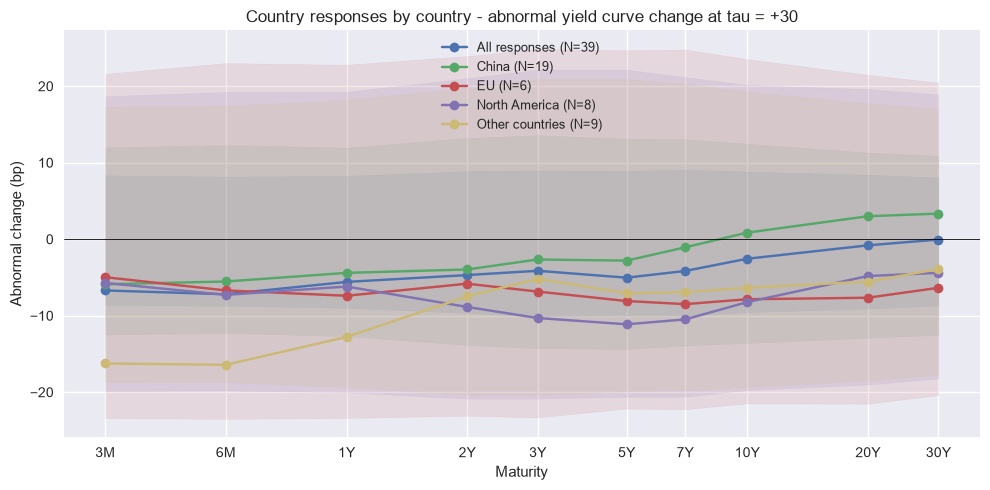

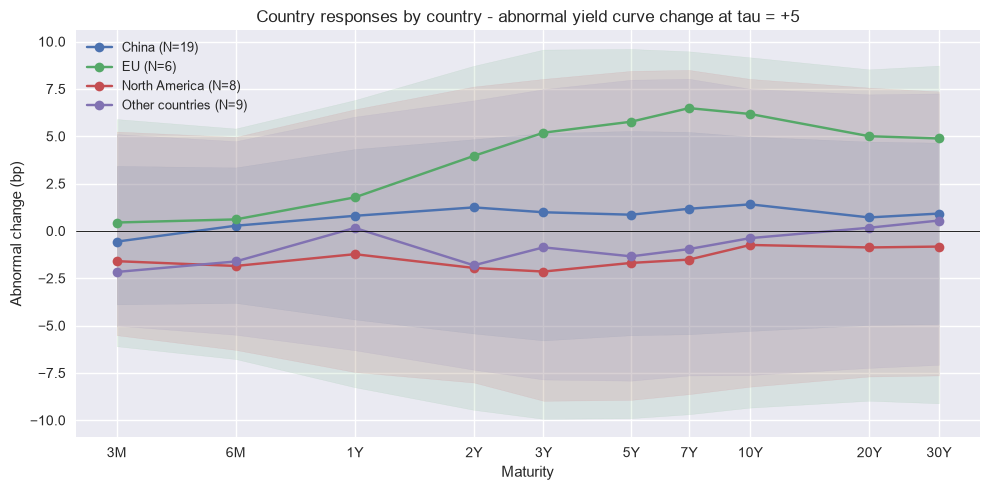

In [20]:
REGIONS = ['China', 'EU', 'North America', 'Other countries']

res_resp_region = {
    r: event_study(yields, responses.filter(pl.col('regions').list.contains(r))['idx'], COLS, exclude_idx=all_event_idx)
    for r in REGIONS
}
res_act_region = {
    r: event_study(yields, actions.filter(pl.col('regions').list.contains(r))['idx'], COLS, exclude_idx=all_event_idx)
    for r in REGIONS + ['Global / other']
}

fig = plot_curve_change({'All responses': res_responses, **res_resp_region}, tau=30,
                        title='Country responses by country', savepath=f'{FIG_DIR}/fig05_responses_region_curve30.png')
plt.show()
fig = plot_curve_change(res_resp_region, tau=5,
                        title='Country responses by country', savepath=f'{FIG_DIR}/fig06_responses_region_curve5.png')
plt.show()

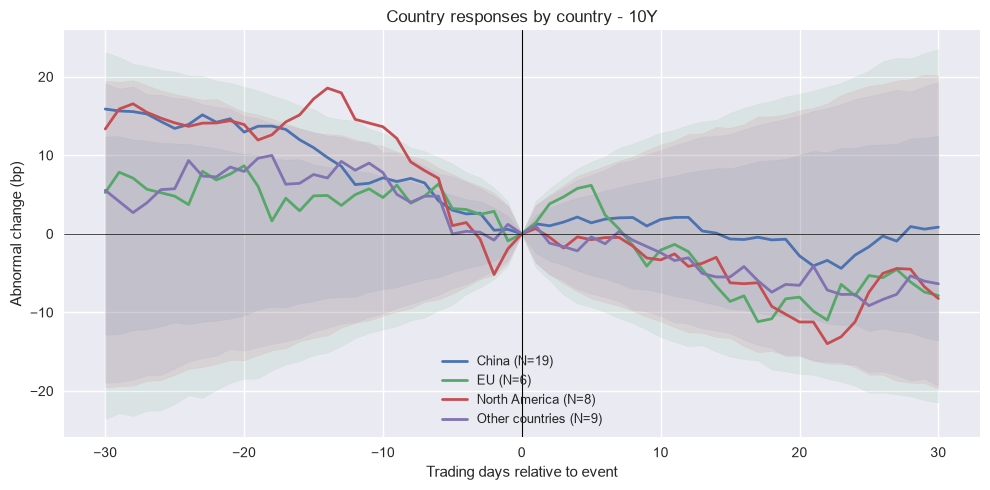

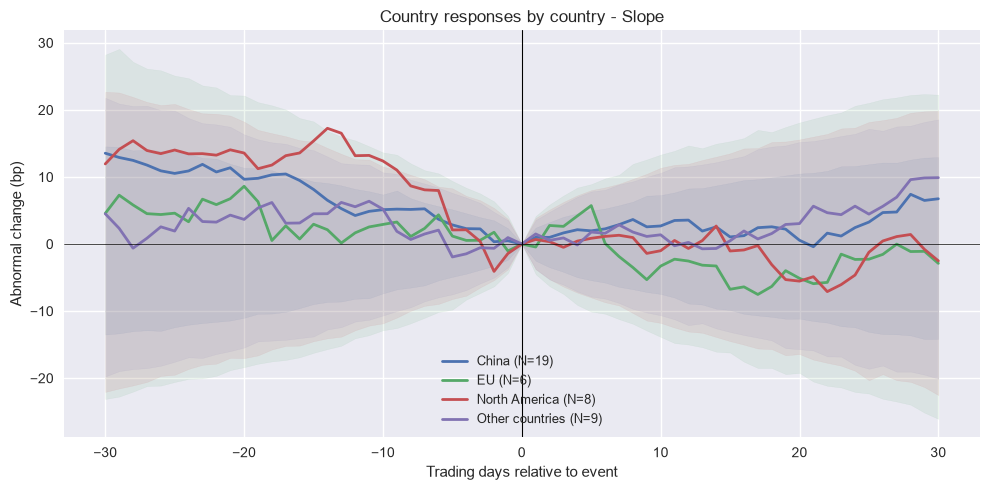

In [21]:
fig = plot_compare_paths(res_resp_region, '10Y', 'Country responses by country', savepath=f'{FIG_DIR}/fig07_responses_region_10y.png')
plt.show()
fig = plot_compare_paths(res_resp_region, 'Slope', 'Country responses by country', savepath=f'{FIG_DIR}/fig08_responses_region_slope.png')
plt.show()

In [22]:
print('Country responses, by responding country:')
display(compare_table({'All responses': res_responses, **res_resp_region}, ['2Y', '10Y', 'Slope'], windows=((-1, 1), (0, 5), (0, 30))))
print("Trump actions, by targeted country:")
display(compare_table({'All actions': res_actions, **res_act_region}, ['2Y', '10Y', 'Slope'], windows=((-1, 1), (0, 5), (0, 30))))

Country responses, by responding country:


sample,N,"2Y [-1,+1]","10Y [-1,+1]","Slope [-1,+1]","2Y [+0,+5]","10Y [+0,+5]","Slope [+0,+5]","2Y [+0,+30]","10Y [+0,+30]","Slope [+0,+30]"
str,i64,str,str,str,str,str,str,str,str,str
"""All responses""",39,"""-1.1""","""0.8""","""0.7""","""0.6""","""1.5""","""2.1""","""-4.7""","""-2.6""","""4.1"""
"""China""",19,"""-1.4""","""0.7""","""0.5""","""1.2""","""1.4""","""2.0""","""-4.0""","""0.9""","""6.7"""
"""EU""",6,"""0.9""","""2.3""","""0.6""","""4.0""","""6.2""","""5.7""","""-5.8""","""-7.9""","""-2.9"""
"""North America""",8,"""0.8""","""2.6""","""2.1""","""-2.0""","""-0.7""","""0.9""","""-8.9""","""-8.2""","""-2.5"""
"""Other countries""",9,"""-2.5""","""-0.2""","""0.5""","""-1.8""","""-0.4""","""1.8""","""-7.5""","""-6.4""","""9.9"""


Trump actions, by targeted country:


sample,N,"2Y [-1,+1]","10Y [-1,+1]","Slope [-1,+1]","2Y [+0,+5]","10Y [+0,+5]","Slope [+0,+5]","2Y [+0,+30]","10Y [+0,+30]","Slope [+0,+30]"
str,i64,str,str,str,str,str,str,str,str,str
"""All actions""",35,"""-1.2""","""0.3""","""0.7""","""-2.1""","""-0.4""","""1.1""","""-13.1**""","""-9.2*""","""-1.8"""
"""China""",18,"""-1.4""","""-0.7""","""-0.1""","""-0.6""","""-0.6""","""0.3""","""-10.0""","""-6.0""","""2.7"""
"""EU""",1,"""-0.3""","""0.8""","""3.1""","""-2.7""","""1.5""","""5.2""","""-16.5""","""-14.4""","""19.1"""
"""North America""",3,"""0.4""","""2.1""","""2.4""","""-1.4""","""1.2""","""2.6""","""-19.8""","""-11.0""","""3.5"""
"""Other countries""",4,"""2.0""","""2.1""","""1.6""","""0.3""","""1.5""","""3.5""","""-15.2""","""-13.9""","""10.1"""
"""Global / other""",14,"""-1.7""","""1.0""","""1.7""","""-4.8""","""-0.6""","""1.7""","""-16.6**""","""-12.4""","""-9.5"""


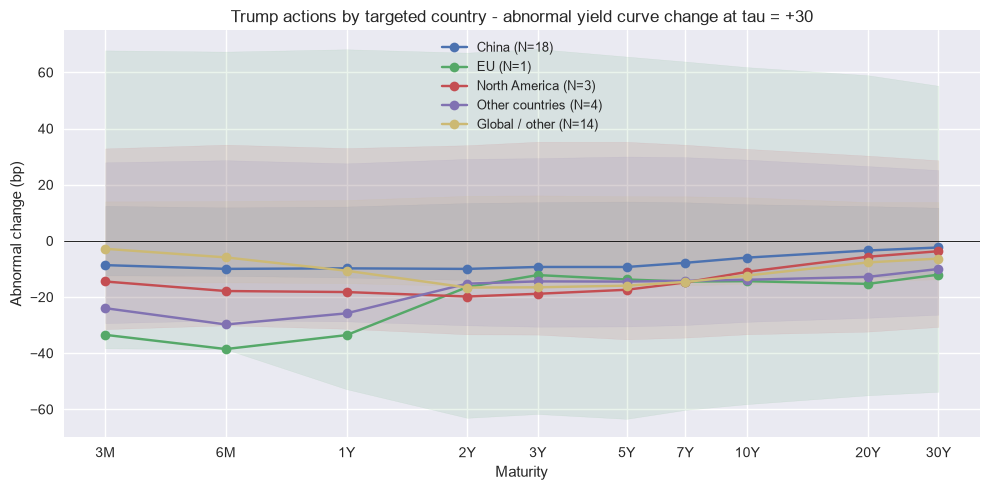

In [23]:
fig = plot_curve_change(res_act_region, tau=30, title='Trump actions by targeted country',
                        savepath=f'{FIG_DIR}/fig09_actions_region_curve30.png')
plt.show()

### Discussion Q1.3

The discussion of Q1.3 is in Section 5 of the report (`main.pdf`). The figures and tables produced above are the ones used there.

## Question 1.4 - First vs second mandate

Rates were near 1.5-2.5% in 2017-2020 and 4-5% in 2025, and the average 30-day change of normal days differs across periods.
We therefore show two benchmarks: (a) all non-event days of the full sample (assignment definition) and (b) non-event days of the
**same mandate** only.

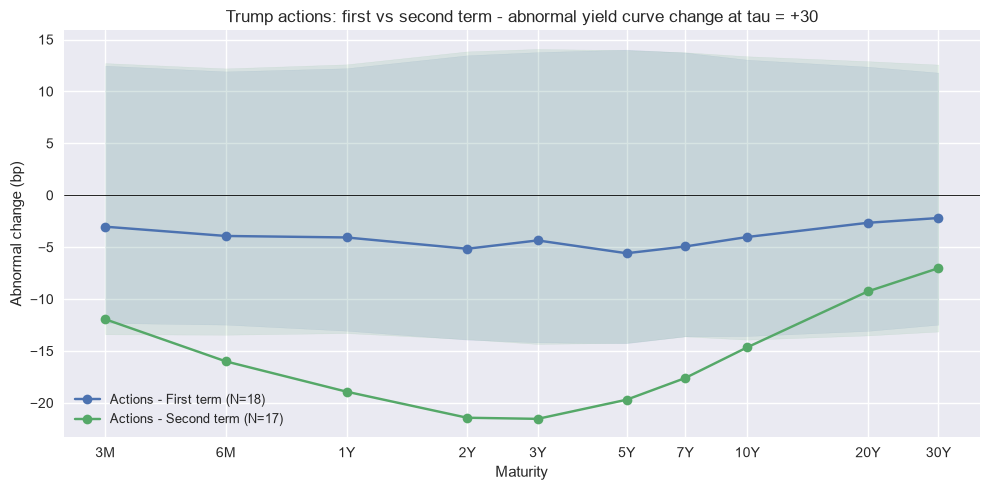

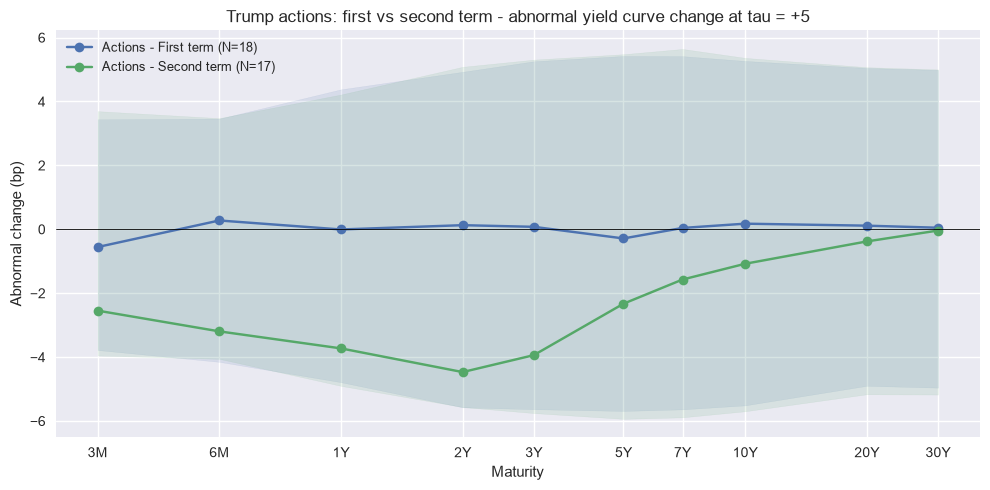

In [24]:
TERMS = {'First term': ('2017-01-20', '2021-01-19'), 'Second term': ('2025-01-20', END_DATE)}

res_term, res_term_same = {}, {}
for cat, tab in [('Actions', actions), ('Responses', responses)]:
    for term, period in TERMS.items():
        idx = tab.filter(pl.col('term') == term)['idx']
        res_term[f'{cat} - {term}'] = event_study(yields, idx, COLS, exclude_idx=all_event_idx)
        res_term_same[f'{cat} - {term}'] = event_study(yields, idx, COLS, exclude_idx=all_event_idx, baseline_period=period)

fig = plot_curve_change({k: v for k, v in res_term.items() if k.startswith('Actions')}, tau=30,
                        title='Trump actions: first vs second term', savepath=f'{FIG_DIR}/fig10_terms_actions_curve30.png')
plt.show()
fig = plot_curve_change({k: v for k, v in res_term.items() if k.startswith('Actions')}, tau=5,
                        title='Trump actions: first vs second term', savepath=f'{FIG_DIR}/fig11_terms_actions_curve5.png')
plt.show()

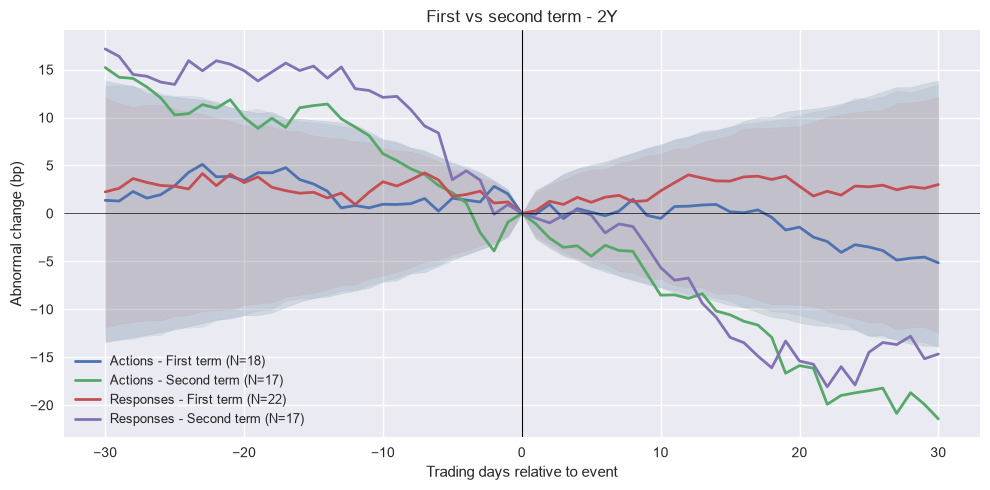

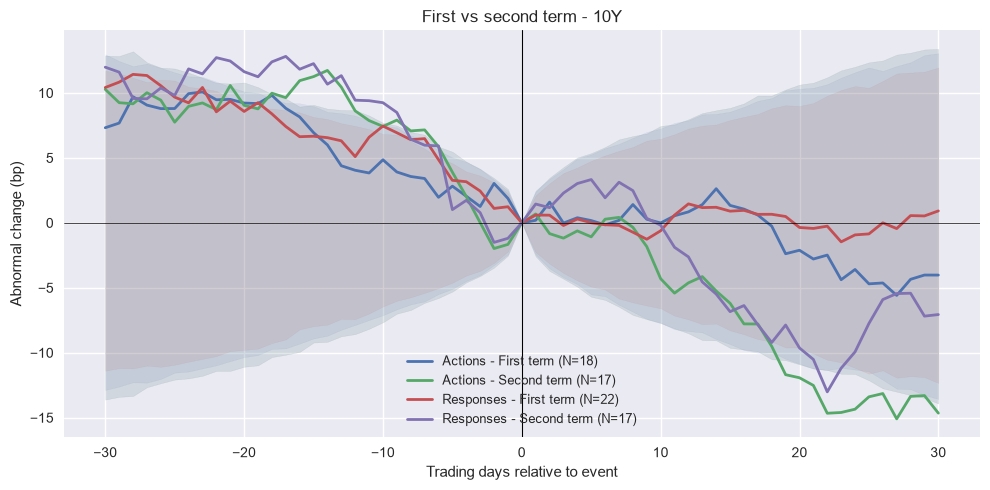

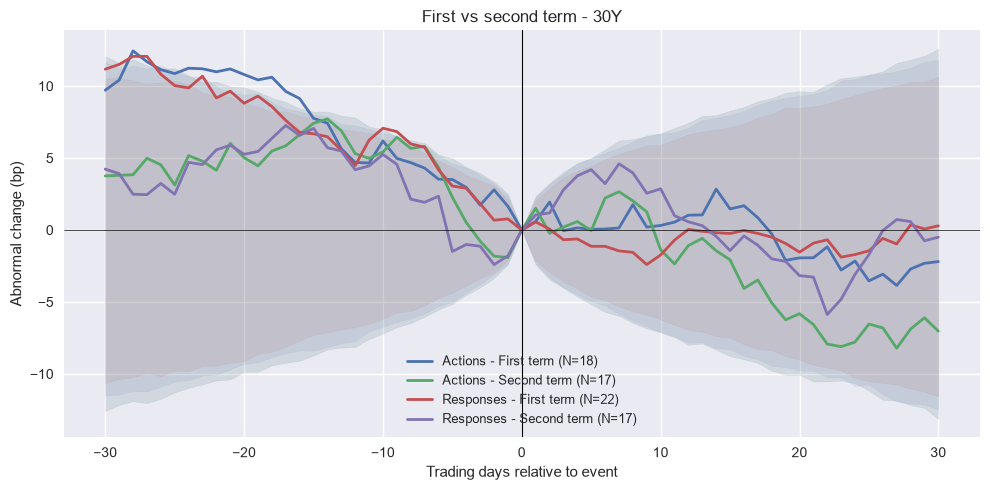

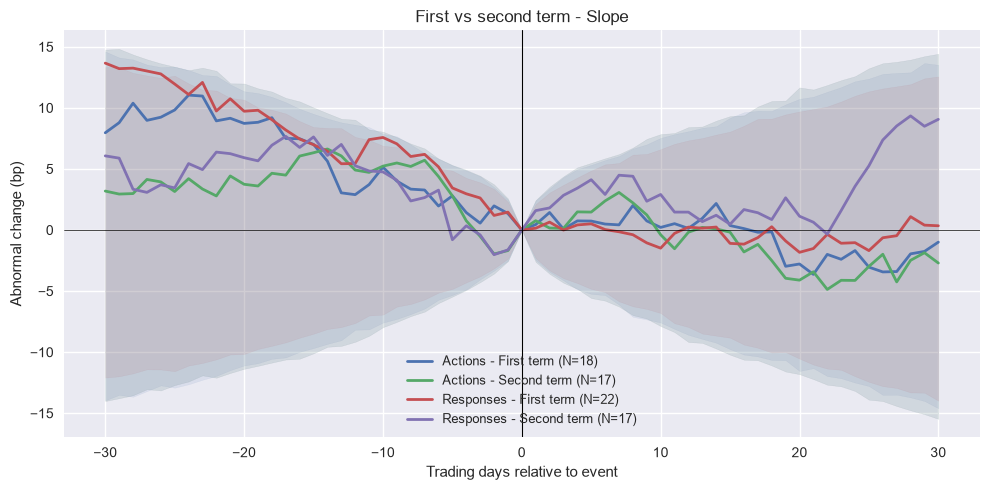

In [25]:
for col in ['2Y', '10Y', '30Y', 'Slope']:
    fig = plot_compare_paths(res_term, col, 'First vs second term', savepath=f'{FIG_DIR}/fig12_terms_{col}.png')
    plt.show()

In [26]:
print('(a) Benchmark = all non-event days (2015-2026)')
display(compare_table(res_term, ['2Y', '10Y', '30Y', 'Slope'], windows=((-1, 1), (0, 5), (0, 30))))
print('(b) Benchmark = non-event days of the same mandate')
display(compare_table(res_term_same, ['2Y', '10Y', '30Y', 'Slope'], windows=((-1, 1), (0, 5), (0, 30))))

(a) Benchmark = all non-event days (2015-2026)


sample,N,"2Y [-1,+1]","10Y [-1,+1]","30Y [-1,+1]","Slope [-1,+1]","2Y [+0,+5]","10Y [+0,+5]","30Y [+0,+5]","Slope [+0,+5]","2Y [+0,+30]","10Y [+0,+30]","30Y [+0,+30]","Slope [+0,+30]"
str,i64,str,str,str,str,str,str,str,str,str,str,str,str
"""Actions - First term""",18,"""-2.1""","""-1.7""","""-1.1""","""-0.9""","""0.1""","""0.2""","""0.0""","""0.7""","""-5.2""","""-4.0""","""-2.2""","""-1.0"""
"""Actions - Second term""",17,"""-0.2""","""2.3""","""3.4*""","""2.4""","""-4.5*""","""-1.1""","""-0.0""","""1.5""","""-21.4***""","""-14.6**""","""-7.0""","""-2.7"""
"""Responses - First term""",22,"""-0.9""","""-0.6""","""-0.2""","""-1.3""","""1.2""","""0.0""","""-1.1""","""0.5""","""3.0""","""0.9""","""0.3""","""0.3"""
"""Responses - Second term""",17,"""-1.4""","""2.6""","""2.8""","""3.2*""","""-0.2""","""3.3""","""4.2*""","""4.1""","""-14.7**""","""-7.1""","""-0.5""","""9.1"""


(b) Benchmark = non-event days of the same mandate


sample,N,"2Y [-1,+1]","10Y [-1,+1]","30Y [-1,+1]","Slope [-1,+1]","2Y [+0,+5]","10Y [+0,+5]","30Y [+0,+5]","Slope [+0,+5]","2Y [+0,+30]","10Y [+0,+30]","30Y [+0,+30]","Slope [+0,+30]"
str,i64,str,str,str,str,str,str,str,str,str,str,str,str
"""Actions - First term""",18,"""-1.6""","""-1.2""","""-0.7""","""-0.8""","""1.4""","""1.4""","""1.1""","""1.0""","""2.8""","""3.1""","""4.0""","""-0.0"""
"""Actions - Second term""",17,"""-0.0""","""2.6*""","""3.5**""","""2.2""","""-4.4*""","""-0.9""","""-0.1""","""0.6""","""-22.5***""","""-17.1***""","""-10.2***""","""-10.0**"""
"""Responses - First term""",22,"""-0.5""","""-0.2""","""0.2""","""-1.3""","""2.5""","""1.2""","""-0.1""","""0.8""","""11.0**""","""8.0""","""6.5""","""1.3"""
"""Responses - Second term""",17,"""-1.3""","""2.8*""","""3.0**""","""3.0**""","""-0.1""","""3.5""","""4.1**""","""3.2""","""-15.8***""","""-9.5**""","""-3.6""","""1.8"""


### Discussion Q1.4

The discussion of Q1.4 is in Section 6 of the report (`main.pdf`). The figures and tables produced above are the ones used there.

## Question 2.1 - Limitations and methodological improvements

We first quantify two weaknesses of the baseline design (overlapping windows and confounding events), then re-run the analysis
with several alternative specifications.

In [27]:
# (1) Overlapping windows: how many OTHER tariff events fall inside each event's [-30,+30] window?
def n_overlaps(idx, others, w=30):
    others = np.asarray(others)
    return np.array([np.sum((np.abs(others - i) <= w) & (others != i)) for i in idx])

ov = n_overlaps(actions['idx'].to_numpy(), all_event_idx)
print(f"Trump actions: on average {ov.mean():.1f} other tariff events inside each +/-30-day window "
      f"(median {np.median(ov):.0f}, max {ov.max()}); only {np.sum(ov == 0)} of {len(ov)} windows are 'clean'.")

# (2) Confounding monetary-policy news: FOMC decision days inside the post-event window
# FOMC statement dates (41): scheduled meetings of 2017-2020 and 2025 plus the unscheduled rate decisions of
# 3 and 15 March 2020 (notation votes excluded). Verified against federalreserve.gov on 28 October 2026.
FOMC = ['2017-02-01','2017-03-15','2017-05-03','2017-06-14','2017-07-26','2017-09-20','2017-11-01','2017-12-13',
        '2018-01-31','2018-03-21','2018-05-02','2018-06-13','2018-08-01','2018-09-26','2018-11-08','2018-12-19',
        '2019-01-30','2019-03-20','2019-05-01','2019-06-19','2019-07-31','2019-09-18','2019-10-30','2019-12-11',
        '2020-01-29','2020-03-03','2020-03-15','2020-04-29','2020-06-10','2020-07-29','2020-09-16','2020-11-05','2020-12-16',
        '2025-01-29','2025-03-19','2025-05-07','2025-06-18','2025-07-30','2025-09-17','2025-10-29','2025-12-10']
fomc_idx = np.searchsorted(dates.to_numpy(), np.array(FOMC, dtype='datetime64[D]'))
post = np.array([np.sum((fomc_idx > i) & (fomc_idx <= i + 30)) for i in actions['idx']])
ann = np.array([np.sum(np.abs(fomc_idx - i) <= 1) for i in actions['idx']])
print(f"{np.mean(post > 0):.0%} of Trump-action windows contain at least one FOMC decision in [+1,+30]; "
      f"{ann.sum()} events have an FOMC decision within +/-1 day.")

Trump actions: on average 6.8 other tariff events inside each +/-30-day window (median 7, max 14); only 2 of 35 windows are 'clean'.
86% of Trump-action windows contain at least one FOMC decision in [+1,+30]; 3 events have an FOMC decision within +/-1 day.


In [28]:
# (3) Alternative specifications for the Trump-action sample
act_idx = actions['idx'].to_numpy()
clean_idx = decluster_events(act_idx, min_gap=30)
no_fomc_idx = act_idx[ann == 0]

specs = {
    'A. Assignment: mean of all non-event days': res_actions,
    'B. Zero benchmark (raw changes)': event_study(yields, act_idx, COLS, exclude_idx=all_event_idx, baseline='zero'),
    'C. Local pre-event drift [-280,-31]': event_study(yields, act_idx, COLS, exclude_idx=all_event_idx, baseline='local'),
    'D. Declustered events (gap > 30 days)': event_study(yields, clean_idx, COLS, exclude_idx=all_event_idx),
    'E. Excl. events with FOMC within +/-1 day': event_study(yields, no_fomc_idx, COLS, exclude_idx=all_event_idx),
}
compare_table(specs, ['2Y', '10Y', 'Slope'], windows=((-1, 1), (0, 5), (0, 30)))

sample,N,"2Y [-1,+1]","10Y [-1,+1]","Slope [-1,+1]","2Y [+0,+5]","10Y [+0,+5]","Slope [+0,+5]","2Y [+0,+30]","10Y [+0,+30]","Slope [+0,+30]"
str,i64,str,str,str,str,str,str,str,str,str
"""A. Assignment: mean of all non-event days""",35,"""-1.2""","""0.3""","""0.7""","""-2.1""","""-0.4""","""1.1""","""-13.1**""","""-9.2*""","""-1.8"""
"""B. Zero benchmark (raw changes)""",35,"""-0.9""","""0.5""","""0.6""","""-1.4""","""0.1""","""0.9""","""-8.6*""","""-5.8""","""-2.9"""
"""C. Local pre-event drift [-280,-31]""",35,"""-0.8""","""0.4""","""0.4""","""-1.3""","""-0.1""","""0.2""","""-7.7""","""-7.1""","""-7.1"""
"""D. Declustered events (gap > 30 days)""",13,"""-2.0""","""-2.0""","""-1.9""","""-2.2""","""-0.9""","""0.2""","""-4.8""","""-4.7""","""-3.3"""
"""E. Excl. events with FOMC within +/-1 day""",32,"""-0.9""","""0.9""","""1.4""","""-1.0""","""0.9""","""2.1""","""-13.4**""","""-8.9*""","""-2.3"""


**Country responses with other benchmarks** (Table 9 of the report): (A) all non-event days, (B) raw changes, (C) benchmark specific to each event. Window $[0,+30]$, in bp.

In [29]:
groups = {'All responses': responses['idx']}
groups.update({r: responses.filter(pl.col('regions').list.contains(r))['idx'] for r in REGIONS})
bench = {'(A) all non-event days': {}, '(B) zero': {'baseline': 'zero'}, '(C) local drift': {'baseline': 'local'}}

res_bench = {(g, b): event_study(yields, idx, COLS, exclude_idx=all_event_idx, **kw)
             for g, idx in groups.items() for b, kw in bench.items()}

def stars(p):
    return '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.10 else ''

rows = []
for g in groups:
    row = {'group': g, 'N': res_bench[(g, '(A) all non-event days')]['n_events']}
    for b in bench:
        r = res_bench[(g, b)]
        eff, pv = window_effect(r, 0, 30)
        for c in ['2Y', '10Y', 'Slope']:
            k = r['columns'].index(c)
            row[f'{b} {c}'] = f"{eff[k]:.1f}{stars(pv[k])}"
    rows.append(row)
pl.DataFrame(rows)

group,N,(A) all non-event days 2Y,(A) all non-event days 10Y,(A) all non-event days Slope,(B) zero 2Y,(B) zero 10Y,(B) zero Slope,(C) local drift 2Y,(C) local drift 10Y,(C) local drift Slope
str,i64,str,str,str,str,str,str,str,str,str
"""All responses""",39,"""-4.7""","""-2.6""","""4.1""","""-0.2""","""0.8""","""3.0""","""-1.6""","""-1.6""","""0.1"""
"""China""",19,"""-4.0""","""0.9""","""6.7""","""0.5""","""4.2""","""5.6""","""-1.3""","""2.8""","""5.4"""
"""EU""",6,"""-5.8""","""-7.9""","""-2.9""","""-1.3""","""-4.5""","""-4.0""","""-3.6""","""-7.7""","""-7.7"""
"""North America""",8,"""-8.9""","""-8.2""","""-2.5""","""-4.4""","""-4.9""","""-3.6""","""-6.0""","""-9.5""","""-12.0"""
"""Other countries""",9,"""-7.5""","""-6.4""","""9.9""","""-3.0""","""-3.0""","""8.8""","""-0.4""","""-5.2""","""1.4"""


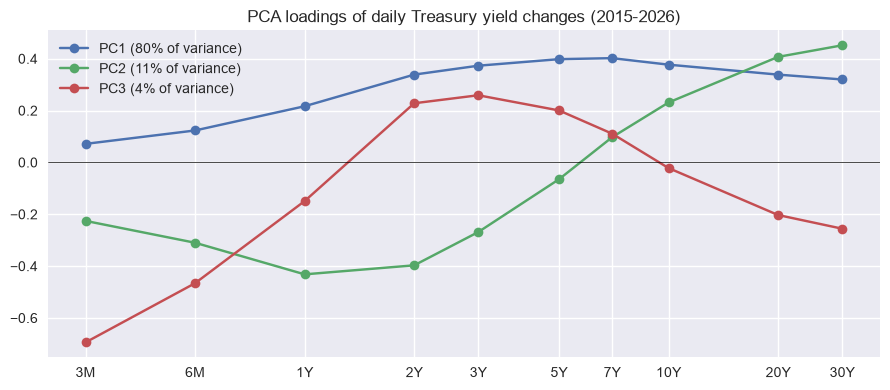

sample,N,"PC1 [-1,+1]","PC2 [-1,+1]","PC3 [-1,+1]","PC1 [+0,+5]","PC2 [+0,+5]","PC3 [+0,+5]","PC1 [+0,+30]","PC2 [+0,+30]","PC3 [+0,+30]"
str,i64,str,str,str,str,str,str,str,str,str
"""Trump actions""",35,"""-0.7""","""2.6**""","""-0.4""","""-3.1""","""2.8""","""0.7""","""-29.6**""","""11.3**""","""3.9"""
"""Country responses""",39,"""0.1""","""2.6**""","""-0.4""","""2.6""","""1.0""","""0.7""","""-10.6""","""8.1""","""5.5"""


In [30]:
# (4) Data-driven curve components: PCA of daily yield changes instead of ad-hoc level/slope/curvature
loadings, evr, scores = pca_factors(yields, n=3)
yields_pc = yields.with_columns([pl.Series(f'PC{j+1}', scores[:, j]) for j in range(3)])
PCS = ['PC1', 'PC2', 'PC3']

fig, ax = plt.subplots(figsize=(9, 4))
for j in range(3):
    ax.plot(MATURITY_YEARS, loadings[:, j], marker='o', label=f'PC{j+1} ({evr[j]:.0%} of variance)')
ax.axhline(0, color='k', lw=0.5)
ax.set_xscale('log'); ax.set_xticks(MATURITY_YEARS); ax.set_xticklabels(MATURITIES)
ax.set_title('PCA loadings of daily Treasury yield changes (2015-2026)')
ax.legend()
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/fig13_pca_loadings.png', dpi=150); fig.savefig(f'{FIG_DIR}/fig13_pca_loadings.pdf', bbox_inches='tight')
plt.show()

res_pc = {
    'Trump actions': event_study(yields_pc, act_idx, PCS, exclude_idx=all_event_idx),
    'Country responses': event_study(yields_pc, responses['idx'], PCS, exclude_idx=all_event_idx),
}
compare_table(res_pc, PCS, windows=((-1, 1), (0, 5), (0, 30)))

In [31]:
# (5) Inference: naive cross-sectional t-test vs placebo test (10Y, Trump actions)
p30 = int(np.where(res_actions['taus'] == 30)[0][0])
k10 = res_actions['columns'].index('10Y')
from scipy.stats import t as student_t
t_stat = res_actions['tstat'][p30, k10]
p_naive = 2 * (1 - student_t.cdf(abs(t_stat), df=res_actions['n_events'] - 1))
print(f"10Y AYC(+30) = {res_actions['abnormal'][p30, k10]:.1f} bp | naive t = {t_stat:.2f} (p = {p_naive:.3f}) "
      f"| placebo p = {res_actions['pval'][p30, k10]:.3f}")

10Y AYC(+30) = -9.2 bp | naive t = -2.12 (p = 0.042) | placebo p = 0.057


### Discussion Q2.1

The discussion of Q2.1 is in Section 7 of the report (`main.pdf`). The figures and tables produced above are the ones used there.